# Лабораторна робота № 8
## Задача комівояжера генетичним і мурашиним алгоритмами

**Інтелектуальний аналіз та візуалізація даних** · 2 години · 4 бали

---

### Постановка

У ЛР5 ви склали піший маршрут: вокзал → 30 пам'яток вашого міста → вокзал. Для 30 точок точний метод не впорався, і ви
взяли найближчого сусіда з доведенням 2-opt. Тепер керівник питає: **«А генетичний алгоритм чи мурахи, про які всі
говорять, дадуть коротший маршрут? І скільки це коштуватиме?»**

Ви відповісте числами: реалізуєте обидва методи (ключові функції пишете самі), запустите їх чесно — з однаковим
бюджетом і по 10 разів — і порівняєте між собою та з результатом ЛР5 за **якістю** і **обчислювальною вартістю**.

### Що здаєте

1. Цей ноутбук із виконаними комірками (перед здачею — «Restart & Run All»; усі виводи збережені).
2. Карту `lr8_маршрут_NN.html` — маршрути ЛР5, ГА, мурах і найкращий на географічній карті (розділ 3.4).
3. Файл `lr8_результат_NN.json`, який створить остання комірка.

**Без карти і без заповненої декларації про використання ШІ (розділ 6) робота не приймається.**

### Як працювати

- Готовий код просто виконуйте. Комірки **ВАШІ ВІДПОВІДІ / ВАШ КОД** заповнюєте ви; після кожної стоїть перевірка
  `assert` — поки вона не проходить, далі не йдіть.
- Числа у звіті беріть з **власних** виводів. Методичні вказівки — у файлі `ЛР8_методичні_вказівки_студенту.docx`.

| Етап | Розділ | Хв |
|---|---|---|
| Дані і відтворення ЛР5 | 0 | 10 |
| Генетичний алгоритм | 1 | 25 |
| Мурашина система | 2 | 25 |
| Порівняння, гібрид і карта | 3 | 15 |
| Звіт колеги на критику | 4 | 10 |
| Звіт, декларація ШІ і результат | 5–6 | 5 |

In [1]:
# встановлення відсутніх пакетів (у Colab зазвичай усе вже є)
import importlib, subprocess, sys
for pkg in ['numpy', 'pandas', 'matplotlib', 'scipy', 'networkx', 'pyarrow', 'shapely', 'folium']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [2]:
import os, glob, json, time, math, hashlib, inspect, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 20)
print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__)

python 3.13.5 | numpy 2.5.5 | pandas 3.0.5 | scipy 1.18.1


### Готовий код

Функції, які вам **не треба** писати: довжина маршруту, лічильник оцінок, найближчий сусід і 2-opt з ЛР5,
мутація-розворот і «двигуни» двох алгоритмів. Прочитайте їх — ваші функції вони викликатимуть.

**Кодування.** Вокзал має номер 0 і стоїть на початку й у кінці маршруту, тому хромосома (genome) — перестановка
решти точок `1…n−1`. **Оцінка якості** — одне обчислення довжини маршруту; бюджет усіх методів вимірюємо в оцінках.

In [3]:
import time, math
import numpy as np


def tour_length(D, genome):
    """Довжина замкненого маршруту: вокзал 0 → genome → вокзал 0. Матриця може бути несиметричною."""
    t = np.concatenate(([0], genome, [0]))
    return float(D[t[:-1], t[1:]].sum())


class Budget:
    """Лічильник оцінок якості: кожен маршрут, довжину якого обчислили, — одна оцінка."""
    def __init__(self, D, limit):
        self.D, self.limit, self.used = D, limit, 0
        self.best_len, self.best = math.inf, None
        self.curve = []                       # (оцінок, найкраща довжина) — для графіка збіжності
    def left(self):
        return self.limit - self.used
    def f(self, genome):
        self.used += 1
        L = tour_length(self.D, genome)
        if L < self.best_len - 1e-9:
            self.best_len, self.best = L, np.array(genome).copy()
            self.curve.append((self.used, L))
        return L


def nearest_neighbour(D):
    """Як у ЛР5: щоразу йти до найближчої невідвіданої точки."""
    n = len(D); cur = 0; left = set(range(1, n)); g = []
    while left:
        nxt = min(left, key=lambda j: D[cur, j]); g.append(nxt); left.discard(nxt); cur = nxt
    return np.array(g)


def two_opt_lr5(D, genome):
    """2-opt з ЛР5: розвертаємо відрізок і щоразу рахуємо довжину повністю (матриця несиметрична). Повертає маршрут і кількість оцінок."""
    best = list(genome); best_len = tour_length(D, best); evals = 1; improved = True
    while improved:
        improved = False
        for i in range(0, len(best) - 1):
            for k in range(i + 1, len(best)):
                cand = best[:i] + best[i:k + 1][::-1] + best[k + 1:]
                cl = tour_length(D, cand); evals += 1
                if cl < best_len - 1e-9:
                    best, best_len, improved = cand, cl, True
    return np.array(best), evals


def reverse_mutation(genome, rng):
    """Мутація-розворот (2-opt): розвернути випадковий відрізок. У несиметричній матриці змінюються не лише два ребра — тому довжину рахуємо повністю."""
    g = genome.copy(); i, k = sorted(rng.choice(len(g), 2, replace=False)); g[i:k + 1] = g[i:k + 1][::-1]
    return g


def run_ga(D, budget, rng, tournament, ox, pop=50, k=2, pm=0.3, elite=2, pc=0.9):
    """Генетичний алгоритм на перестановках. tournament і ox — ваші функції."""
    n = len(D) - 1; B = Budget(D, budget); t0 = time.perf_counter()
    P = [rng.permutation(np.arange(1, n + 1)) for _ in range(pop)]; F = np.array([B.f(g) for g in P])
    while B.left() > 0:
        order = np.argsort(F); Q = [P[i].copy() for i in order[:elite]]; FQ = [F[i] for i in order[:elite]]
        while len(Q) < pop and B.left() > 0:
            a, b = P[tournament(F, k, rng)], P[tournament(F, k, rng)]
            if rng.random() < pc:
                i, j = sorted(rng.choice(n, 2, replace=False)); c = ox(a, b, i, j)
            else:
                c = a.copy()
            if rng.random() < pm:
                c = reverse_mutation(c, rng)
            Q.append(c); FQ.append(B.f(c))
        P, F = Q, np.array(FQ)
    return {'довжина': B.best_len, 'маршрут': B.best, 'оцінок': B.used, 'час_с': time.perf_counter() - t0, 'крива': B.curve}


def run_aco(D, budget, rng, choose_next, update_pheromone, ants=31, alpha=1.0, beta=2.0, rho=0.5):
    """Мурашина система. choose_next і update_pheromone — ваші функції."""
    n = len(D); B = Budget(D, budget); t0 = time.perf_counter()
    eta = 1.0 / np.maximum(D, 1.0)            # близькість; 1 м замість 0 — щоб не ділити на нуль для «злиплих» точок
    nn = nearest_neighbour(D); tau = np.full((n, n), ants / tour_length(D, nn))
    while B.left() > 0:
        tours, lens = [], []
        for _ in range(min(ants, B.left())):
            cur, left, g = 0, list(range(1, n)), []
            while left:
                nxt = choose_next(cur, left, tau, eta, alpha, beta, rng); g.append(nxt); left.remove(nxt); cur = nxt
            g = np.array(g); tours.append(g); lens.append(B.f(g))
        tau = update_pheromone(tau, tours, lens, rho)
    return {'довжина': B.best_len, 'маршрут': B.best, 'оцінок': B.used, 'час_с': time.perf_counter() - t0, 'крива': B.curve}


def mann_whitney(x, y):
    from scipy.stats import mannwhitneyu
    return float(mannwhitneyu(x, y, alternative='two-sided').pvalue)

---
## 0. Ваш варіант і дані

Варіант той самий, що в ЛР5: ваше місто і ваші 31 точка. Покладіть поруч із ноутбуком файл `lr5_результати.json`,
який ви здали в ЛР5, і **теку знімка міста з ЛР5** (`osm_<місто>` з файлами `road_nodes.parquet` і `road_edges.parquet`) —
з неї маршрути на карті підуть вулицями. Якщо ЛР5 у вас немає, ноутбук візьме запасний файл викладача (Львів) — це буде видно
в результаті, і викладач врахує.

In [4]:
STUDENT_NAME = 'Бісюк Роман Васильович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 1      # номер у списку групи
# файл ЛР5 лежить не поруч із ноутбуком, а в сусідній теці lab5 — тому вказуємо шлях до неї
LR5_FILE     = os.path.join('..', 'lab5', 'lr5_результати.json')

In [5]:
assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
FALLBACK = os.path.join('дані', 'lr5_результати_запасний_Львів.json')
if os.path.exists(LR5_FILE):
    SOURCE = 'свої'
else:
    print('УВАГА: файл %s не знайдено — беру запасний файл викладача (Львів).' % LR5_FILE)
    LR5_FILE, SOURCE = FALLBACK, 'запасні'
LR5 = json.load(open(LR5_FILE, encoding='utf-8'))
BIG = LR5['велика_задача']
if SOURCE == 'свої' and LR5.get('номер') not in (None, LIST_NUMBER):
    print('УВАГА: у файлі ЛР5 номер %s, а ви вказали %s. Це точно ваш файл?' % (LR5.get('номер'), LIST_NUMBER))
raw = BIG['матриця_віддалей_м']
assert all(v is not None for row in raw for v in row), 'у матриці є порожні віддалі (недосяжні точки) — поверніться до кроку 4 ЛР5'
D = np.array(raw, dtype=float)
n = len(D)
assert D.shape == (n, n) and n >= 10, 'матриця має бути квадратною'
NAMES = [p['name'] for p in BIG['точки']]
D_MD5 = hashlib.md5(json.dumps(raw).encode()).hexdigest()[:10]
zeros = int(((D == 0) & ~np.eye(n, dtype=bool)).sum())
asym = float(np.max(np.abs(D - D.T)))
print('місто:', LR5.get('місто'), '| дані:', SOURCE, '| точок:', n, '| контрольна сума матриці:', D_MD5)
print('найбільша різниця «туди» і «назад»: %.0f м' % asym)
print('нульових віддалей між різними точками: %d' % zeros + ('  ← точки «злиплися» на одному вузлі графа (див. ЛР5, крок 4)' if zeros else ''))

місто: Львів, Україна | дані: свої | точок: 31 | контрольна сума матриці: ce30d02814
найбільша різниця «туди» і «назад»: 0 м
нульових віддалей між різними точками: 0


### Відтворюємо ЛР5 — і отримуємо базу порівняння

Найближчий сусід + 2-opt детерміновані, тому на вашій матриці мають дати **рівно** ту саму довжину, що в ЛР5.
Заодно міряємо їхній час **на цьому комп'ютері** — порівнювати час можна лише на одній машині.

In [6]:
t0 = time.perf_counter(); NN = nearest_neighbour(D); t_nn = time.perf_counter() - t0
t0 = time.perf_counter(); OPT2, EVALS_2OPT = two_opt_lr5(D, list(NN)); t_2opt = time.perf_counter() - t0
L_NN, L_2OPT = tour_length(D, NN), tour_length(D, OPT2)
print('найближчий сусід: %.1f м (ЛР5: %s)' % (L_NN, BIG['найближчий_сусід_м']))
print('2-opt:            %.1f м (ЛР5: %s) | %d оцінок | %.4f с' % (L_2OPT, BIG['двоопт_м'], EVALS_2OPT, t_2opt))
LR5_OK = abs(L_2OPT - BIG['двоопт_м']) < 1.0
print('збігається з ЛР5' if LR5_OK else 'НЕ збігається з ЛР5: матриця або код ЛР5 змінювались — напишіть про це у звіті')

найближчий сусід: 25417.4 м (ЛР5: 25417.3)
2-opt:            23390.5 м (ЛР5: 23390.2) | 1741 оцінок | 0.0319 с
збігається з ЛР5


**Висновок 0.** Дані ЛР5 завантажено (свої, Львів, 31 точка, матриця симетрична). Найближчий сусід (25 417 м) і 2-opt (23 390 м, 1741 оцінка)
дали ті самі довжини, що в ЛР5 (різниця 0,3 м — лише округлення), тож база для порівняння правильна.

---
## 1. Генетичний алгоритм

Цикл (лекція 11, розділ 3): відібрати двох батьків турніром → схрестити OX → іноді мутувати розворотом → оцінити.
Дві найкращі особини переходять у нове покоління без змін (еліта). «Двигун» `run_ga` готовий; ви пишете дві функції.

**1.1. Турнір.** З популяції навмання (з поверненням) беремо `k` особин і повертаємо **індекс** найкоротшої.
`F` — масив довжин маршрутів популяції, `rng` — генератор `np.random.default_rng`.

**1.2. Упорядковане схрещування OX.** Нащадок отримує відрізок `p1[i..j]` (включно) на тих самих позиціях; решту
генів дописуємо в тому порядку, у якому вони йдуть у `p2`, починаючи з позиції `j+1` і по колу, пропускаючи ті,
що вже є, і ставлячи їх на вільні місця теж починаючи з позиції `j+1` по колу. Приклад із лекції:
`p1 = [1 2 3 4 5 6 7 8]`, `p2 = [5 7 1 8 3 6 2 4]`, `i = 2`, `j = 4` → `[1 8 3 4 5 6 2 7]`.

In [7]:
# ----- ВАШ КОД -----
def tournament(F, k, rng):
    idx = rng.integers(0, len(F), size=k)      # k випадкових особин (з поверненням)
    return int(idx[np.argmin(F[idx])])         # індекс тієї, у якої маршрут найкоротший

def ox(p1, p2, i, j):
    child = p1.copy()                          # відрізок p1[i..j] уже стоїть на своїх місцях
    used = set(p1[i:j + 1])
    rest = [g for g in np.roll(p2, -(j + 1)) if g not in used]   # p2 починаючи з j+1 по колу, без уже взятих
    for s, g in enumerate(rest):
        child[(j + 1 + s) % len(p1)] = g       # ставимо на вільні місця теж з j+1 по колу
    return child
# ----- КІНЕЦЬ -----

In [8]:
# перевірка ваших функцій
_r = np.random.default_rng(0); _F = np.array([5.0, 1.0, 9.0, 3.0])
assert isinstance(tournament(_F, 2, _r), (int, np.integer)), 'турнір має повертати індекс (ціле число)'
assert tournament(_F, 200, _r) == 1, 'при великому k турнір має майже завжди повертати найкращого'
_freq = np.mean([tournament(_F, 2, _r) == 1 for _ in range(4000)])
assert abs(_freq - (1 - 0.75 ** 2)) < 0.04, 'при k = 2 найкращий має вигравати приблизно в 44 %% випадків, у вас %.0f %%' % (100 * _freq)
_c = ox(np.array([1, 2, 3, 4, 5, 6, 7, 8]), np.array([5, 7, 1, 8, 3, 6, 2, 4]), 2, 4)
assert list(_c) == [1, 8, 3, 4, 5, 6, 2, 7], 'OX на прикладі з лекції дав %s' % list(_c)
for _ in range(200):
    _a, _b = _r.permutation(np.arange(1, 31)), _r.permutation(np.arange(1, 31)); _i, _j = sorted(_r.choice(30, 2, replace=False))
    _c = ox(_a, _b, _i, _j)
    assert sorted(_c) == list(range(1, 31)), 'нащадок OX має бути перестановкою без повторів'
    assert list(_c[_i:_j + 1]) == list(_a[_i:_j + 1]), 'відрізок батька 1 має стояти на тих самих місцях'
GA_TESTS_OK = True
print('обидві функції працюють')

обидві функції працюють


**1.3. Параметри і запуск.** Бюджет — **20 000 оцінок** на запуск, **10 запусків** із сідами 1…10 — однаково для
всіх методів. Типові параметри ГА (лекція 11): популяція 50, турнір 2, еліта 2, схрещування 0,9, мутація 0,3.
Можете змінити `GA_PARAMS` — але спершу подивіться на коротку перевірку двох значень мутації нижче й поясніть свій
вибір у звіті.

In [9]:
BUDGET, RUNS = 20_000, 10
for pm in [0.1, 0.3]:
    res = [run_ga(D, BUDGET, np.random.default_rng(100 + s), tournament, ox, pm=pm)['довжина'] for s in range(3)]
    print('мутація %.1f: медіана трьох пробних запусків %.0f м' % (pm, np.median(res)))

мутація 0.1: медіана трьох пробних запусків 22553 м


мутація 0.3: медіана трьох пробних запусків 25568 м


In [10]:
# ----- ВАШІ ВІДПОВІДІ -----
# пробні запуски: мутація 0.1 дала коротший маршрут, ніж 0.3, тому беру 0.1
GA_PARAMS = {'pop': 50, 'k': 2, 'pm': 0.1, 'elite': 2}
# ----- КІНЕЦЬ -----

In [11]:
assert set(GA_PARAMS) == {'pop', 'k', 'pm', 'elite'}
GA = [run_ga(D, BUDGET, np.random.default_rng(s), tournament, ox, **GA_PARAMS) for s in range(1, RUNS + 1)]
print('ГА: медіана %.0f м, найкращий %.0f м, медіанний час %.2f с на запуск' % (np.median([r['довжина'] for r in GA]), min(r['довжина'] for r in GA), np.median([r['час_с'] for r in GA])))

ГА: медіана 22963 м, найкращий 22004 м, медіанний час 3.16 с на запуск


**Висновок 1.** Мутація 0,1 виявилась кращою за 0,3 (22 553 м проти 25 568 м), тому взяв її. З 10 запусків ГА дав медіану 22 963 м — трохи
коротше за 2-opt ЛР5, а найкращий запуск 22 004 м. Але розкид великий: найгірший запуск 24 322 м — гірше за ЛР5.

---
## 2. Мурашина система

Кожна «мураха» будує маршрут від вокзалу, обираючи наступну точку з імовірністю (лекція 11, розділ 5)

$$P(i \to j) = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l \in \text{невідвідані}} \tau_{il}^{\alpha}\,\eta_{il}^{\beta}}, \qquad \eta_{ij} = \frac{1}{d_{ij}},$$

а після того як усі мурахи ітерації побудували маршрути, феромон випаровується і поповнюється:

$$\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij} + \sum_{k:\,(i \to j) \in T_k} \frac{1}{L(T_k)}.$$

Матриця несиметрична, тож ребро має **напрям**: маршрут, що йде з `i` в `j`, поповнює `tau[i, j]`, а не `tau[j, i]`.
Не забудьте ребра від вокзалу до першої точки і від останньої точки до вокзалу.

**2.1.** `choose_next(cur, left, tau, eta, alpha, beta, rng)` — повертає номер наступної точки зі списку
невідвіданих `left`. **2.2.** `update_pheromone(tau, tours, lens, rho)` — повертає **нову** матрицю феромону;
`tours` — список хромосом (без вокзалу), `lens` — їхні довжини.

In [12]:
# ----- ВАШ КОД -----
def choose_next(cur, left, tau, eta, alpha, beta, rng):
    w = tau[cur, left] ** alpha * eta[cur, left] ** beta     # «привабливість» кожної невідвіданої точки
    return int(rng.choice(left, p=w / w.sum()))              # вибір з імовірністю, пропорційною привабливості

def update_pheromone(tau, tours, lens, rho):
    new = (1 - rho) * tau                                    # випаровування
    for g, L in zip(tours, lens):
        t = np.concatenate(([0], g, [0]))                    # додаємо вокзал на початок і в кінець
        new[t[:-1], t[1:]] += 1.0 / L                        # поповнюємо направлені ребра i -> j
    return new
# ----- КІНЕЦЬ -----

In [13]:
# перевірка ваших функцій
_r = np.random.default_rng(1); _tau = np.ones((4, 4)); _eta = np.array([[0, 1, 2, 3]] * 4, dtype=float)
_pick = [choose_next(0, [1, 2, 3], _tau, _eta, 1.0, 1.0, _r) for _ in range(6000)]
_fr = [np.mean(np.array(_pick) == j) for j in (1, 2, 3)]
assert all(abs(f - p) < 0.03 for f, p in zip(_fr, [1 / 6, 2 / 6, 3 / 6])), 'частоти вибору %s не відповідають імовірностям 1/6, 2/6, 3/6' % np.round(_fr, 3)
_fr0 = [np.mean(np.array([choose_next(0, [1, 2, 3], _tau, _eta, 1.0, 0.0, _r) for _ in range(3000)]) == j) for j in (1, 2, 3)]
assert all(abs(f - 1 / 3) < 0.04 for f in _fr0), 'при beta = 0 і однаковому феромоні вибір має бути рівноймовірним'
_new = update_pheromone(np.ones((4, 4)), [np.array([1, 2, 3])], [10.0], 0.5)
_exp = np.full((4, 4), 0.5); _exp[[0, 1, 2, 3], [1, 2, 3, 0]] += 0.1
assert _new.shape == (4, 4) and np.allclose(_new, _exp), 'феромон після оновлення не той; очікувалося\n%s' % _exp
ACO_TESTS_OK = True
print('обидві функції працюють')

обидві функції працюють


**2.3. Параметри і запуск.** Типові параметри (лекція 11): мурах стільки, скільки точок, α = 1, β = 2, ρ = 0,5.
Близькість η = 1/d, але для «злиплих» точок з нульовою віддаллю ділимо на 1 м, а не на нуль (див. `run_aco`).
Запуск займе 1–3 хвилини. Спершу коротка перевірка: що буде без близькості (β = 0)?

In [14]:
for beta in [0.0, 2.0]:
    res = [run_aco(D, 3000, np.random.default_rng(200 + s), choose_next, update_pheromone, beta=beta)['довжина'] for s in range(2)]
    print('beta = %.0f: медіана двох коротких запусків (3 000 оцінок) %.0f м' % (beta, np.median(res)))

beta = 0: медіана двох коротких запусків (3 000 оцінок) 38458 м


beta = 2: медіана двох коротких запусків (3 000 оцінок) 23149 м


In [15]:
# ----- ВАШІ ВІДПОВІДІ -----
# стандартні параметри з лекції; пробний запуск показав, що beta = 2 набагато краще за beta = 0
ACO_PARAMS = {'ants': n, 'alpha': 1.0, 'beta': 2.0, 'rho': 0.5}
# ----- КІНЕЦЬ -----

In [16]:
assert set(ACO_PARAMS) == {'ants', 'alpha', 'beta', 'rho'}
ACO = [run_aco(D, BUDGET, np.random.default_rng(s), choose_next, update_pheromone, **ACO_PARAMS) for s in range(1, RUNS + 1)]
print('мурахи: медіана %.0f м, найкращий %.0f м, медіанний час %.2f с на запуск' % (np.median([r['довжина'] for r in ACO]), min(r['довжина'] for r in ACO), np.median([r['час_с'] for r in ACO])))

мурахи: медіана 22937 м, найкращий 22518 м, медіанний час 46.96 с на запуск


**Висновок 2.** Без близькості (β = 0) мурахи ходять майже навмання — 38 458 м, а з β = 2 — 23 149 м уже за 3000 оцінок. З повним бюджетом
медіана мурах 22 937 м, найкращий 22 518 м, найгірший 23 400 м — стабільніше за ГА, але один запуск триває ~47 с.

---
## 3. Порівняння і гібрид

### 3.1. Таблиця: якість і вартість

Розрив рахуємо від **2-opt з ЛР5** (оптимум для 31 точки вам невідомий). Від'ємний розрив — метод **кращий** за ЛР5.

In [17]:
def summary(name, runs):
    L = np.array([r['довжина'] for r in runs]); T = np.array([r['час_с'] for r in runs])
    return {'метод': name, 'медіана, м': round(float(np.median(L))), 'найкращий, м': round(float(L.min())), 'найгірший, м': round(float(L.max())),
            'розрив медіани від 2-opt ЛР5, %': round(100 * (np.median(L) / L_2OPT - 1), 1), 'оцінок': int(np.median([r['оцінок'] for r in runs])),
            'час, с (медіана)': round(float(np.median(T)), 3), 'у скільки разів довше за 2-opt': round(float(np.median(T) / max(t_2opt, 1e-6)))}
TABLE = pd.DataFrame([
    {'метод': 'найближчий сусід (ЛР5)', 'медіана, м': round(L_NN), 'найкращий, м': round(L_NN), 'найгірший, м': round(L_NN), 'розрив медіани від 2-opt ЛР5, %': round(100 * (L_NN / L_2OPT - 1), 1),
     'оцінок': 1, 'час, с (медіана)': round(t_nn, 4), 'у скільки разів довше за 2-opt': round(t_nn / max(t_2opt, 1e-6), 2)},
    {'метод': '2-opt (ЛР5)', 'медіана, м': round(L_2OPT), 'найкращий, м': round(L_2OPT), 'найгірший, м': round(L_2OPT), 'розрив медіани від 2-opt ЛР5, %': 0.0,
     'оцінок': EVALS_2OPT, 'час, с (медіана)': round(t_2opt, 4), 'у скільки разів довше за 2-opt': 1},
    summary('генетичний алгоритм', GA), summary('мурашина система', ACO)]).set_index('метод')
P_GA_ACO = mann_whitney([r['довжина'] for r in GA], [r['довжина'] for r in ACO])
display(TABLE)
print('ГА проти мурах: тест Манна — Вітні, p = %.4f' % P_GA_ACO + (' — різниця значуща' if P_GA_ACO < 0.05 else ' — різниця не доведена'))

,"медіана, м","найкращий, м","найгірший, м","розрив медіани від 2-opt ЛР5, %",оцінок,"час, с (медіана)",у скільки разів довше за 2-opt
метод,,,,,,,
найближчий сусід (ЛР5),25417,25417,25417,8.7,1,0.0004,0.01
2-opt (ЛР5),23390,23390,23390,0.0,1741,0.0319,1.00
генетичний алгоритм,22963,22004,24322,-1.8,20000,3.1620,99.00
мурашина система,22937,22518,23400,-1.9,20000,46.9620,1471.00


ГА проти мурах: тест Манна — Вітні, p = 0.5708 — різниця не доведена


**Висновок 3.1.** Обидві метаевристики в медіані лише на ~1,8–1,9 % коротші за 2-opt ЛР5, а коштують набагато більше: ГА ~3 с
(у ~100 разів довше), мурахи ~47 с (у ~1500 разів довше). Різниця між ГА і мурахами не значуща (p = 0,57).

### 3.2. Збіжність

Медіана (з 10 запусків) найкращої довжини залежно від кількості оцінок. Горизонтальні лінії — результати ЛР5.

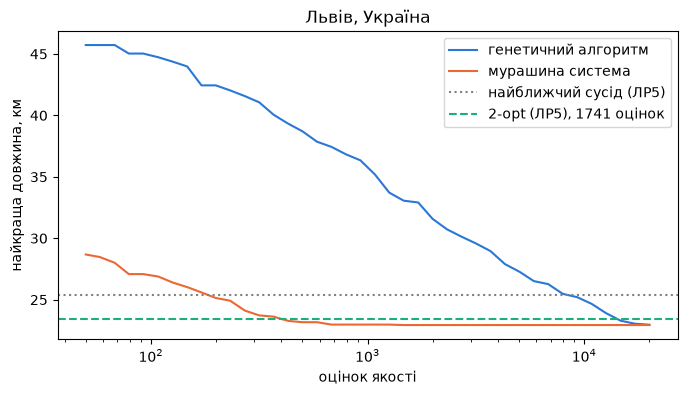

In [18]:
CHECK = np.unique(np.round(np.logspace(np.log10(50), np.log10(BUDGET), 40)).astype(int))
def median_curve(runs):
    out = []
    for c in CHECK:
        vals = [min([L for e, L in r['крива'] if e <= c], default=np.nan) for r in runs]
        out.append(np.nanmedian(vals))
    return out
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(CHECK, np.array(median_curve(GA)) / 1000, label='генетичний алгоритм', color='#2a78d6')
ax.plot(CHECK, np.array(median_curve(ACO)) / 1000, label='мурашина система', color='#eb6834')
ax.axhline(L_NN / 1000, ls=':', color='grey', label='найближчий сусід (ЛР5)')
ax.axhline(L_2OPT / 1000, ls='--', color='#1baf7a', label='2-opt (ЛР5), %d оцінок' % EVALS_2OPT)
ax.set_xscale('log'); ax.set_xlabel('оцінок якості'); ax.set_ylabel('найкраща довжина, км'); ax.legend(); ax.set_title(str(LR5.get('місто')))
plt.show()

**Висновок 3.2.** Мурахи збігаються дуже швидко: вже після ~400 оцінок вони на рівні 2-opt, а далі майже не покращуються. ГА стартує
з випадкових маршрутів (~45 км) і доходить до рівня 2-opt лише під кінець бюджету (~15 000 оцінок). 2-opt досягає того ж за 1741 оцінку.

### 3.3. Гібрид: доводимо найкращий маршрут 2-opt

Беремо найкращий маршрут кожного методу і доводимо його тим самим 2-opt, що в ЛР5. Оцінки й час 2-opt **додаємо**
до вартості методу. Чи вдається побити результат ЛР5 і якою ціною?

In [19]:
def polish(runs):
    best = min(runs, key=lambda r: r['довжина']); t0 = time.perf_counter()
    g, ev = two_opt_lr5(D, list(best['маршрут'])); t = time.perf_counter() - t0
    return {'до 2-opt, м': round(best['довжина']), 'після 2-opt, м': round(tour_length(D, g)), 'додатково оцінок': ev,
            'додатково, с': round(t, 4), 'краще за ЛР5 на, %': round(100 * (1 - tour_length(D, g) / L_2OPT), 1), 'маршрут': g}
HYB = {'ГА + 2-opt': polish(GA), 'мурахи + 2-opt': polish(ACO)}
display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != 'маршрут'} for k, v in HYB.items()}).T)
BEST_NAME = min(HYB, key=lambda k: HYB[k]['після 2-opt, м']); BEST_TOUR = HYB[BEST_NAME]['маршрут']
BEAT_LR5 = HYB[BEST_NAME]['після 2-opt, м'] < L_2OPT - 0.5
print('найкоротший маршрут: %s, %.0f м — %s' % (BEST_NAME, tour_length(D, BEST_TOUR), 'КОРОТШИЙ за ЛР5' if BEAT_LR5 else 'не коротший за ЛР5'))
print('порядок:', ' → '.join([NAMES[0]] + [NAMES[i] for i in BEST_TOUR] + [NAMES[0]]))

,"до 2-opt, м","після 2-opt, м",додатково оцінок,"додатково, с","краще за ЛР5 на, %"
ГА + 2-opt,22004.0,22004.0,436.0,0.0067,5.9
мурахи + 2-opt,22518.0,21931.0,1306.0,0.0283,6.2


найкоротший маршрут: мурахи + 2-opt, 21931 м — КОРОТШИЙ за ЛР5
порядок: СТАРТ: Львів-Головний → Музей історії Львівської залізниці → Національний музей "Тюрма на Лонцького" → Арсенал Сенявських → Музично-меморіальний музей С. Крушельницької → Палац Потоцьких → Музей мистецтва давньої української книги → Львівська національна галерея мистецтв → Львівська цитадель → Музей Івана Франка → Музей Михайла Грушевського → Музей хвороб людини → Іван Франко → Володимир Івасюк → Музей народної архітектури і побуту імені Климентія Шептицького „Шевченківський гай“ → Музей сакральної барокової скульптури Пінзеля → Арсенал, Львівський державний історичний музей старовинної зброї → Палац Любомирських → Порохова Вежа → Вежа Корнякта → Королівський арсенал → Львівський музей історії релігії → Музей скла → Кам'яниця Корнякта → Музей міста → Львівський історичний музей → Музей етнографії та художнього промислу → Львівський Державний Природознавчий Музей → Національний музей у Львові → Музей пам'яток старод

**Висновок 3.3.** Гібрид спрацював: мурахи + 2-opt дали 21 931 м — на 6,2 % коротше за ЛР5, і 2-opt додав лише 1306 оцінок (0,03 с).
Маршрут ГА (22 004 м) 2-opt не покращив — він уже був локальним оптимумом.

### 3.4. Маршрути на географічній карті

Числа в таблиці — це ще не маршрут. Покажемо на карті міста **маршрут ЛР5 (2-opt)**, **найкращі маршрути ГА і мурах**
і **найкращий маршрут загалом**. Лінії йдуть **вулицями** — тими самими найкоротшими шляхами пішохідної мережі, з яких
у ЛР5 складено матрицю віддалей. Для цього потрібна тека знімка вашого міста з ЛР5 (`osm_<місто>`). Ноутбук перевірить,
що мережа з теки дає **ті самі** віддалі, що й матриця; якщо теки немає або вона від іншого міста — лінії будуть
прямими відрізками з попередженням (так карта менш точна; поясніть причину у звіті).

Номери на маркерах — порядок обходу в найкращому маршруті. Шари вмикаються в правому верхньому куті карти.

In [20]:
# ----- ВАШІ ВІДПОВІДІ -----
NETWORK_DIR = os.path.join('..', 'lab5', 'osm_львів')      # тека знімка з ЛР5 лежить у lab5
# ----- КІНЕЦЬ -----

In [21]:
import networkx as nx
import folium
from xyzservices import providers as xyz
BASEMAP = xyz.Esri.WorldGrayCanvas          # CARTO з 2026 р. вимагає ключ API
LAT = np.array([p['lat'] for p in BIG['точки']]); LON = np.array([p['lon'] for p in BIG['точки']])

def load_network(folder):
    """Пішохідна мережа з теки ЛР5: орієнтований граф, вузли точок, геометрія ребер."""
    nodes = pd.read_parquet(os.path.join(folder, 'road_nodes.parquet'), columns=['osmid', 'x', 'y'])
    edges = pd.read_parquet(os.path.join(folder, 'road_edges.parquet'))
    G = nx.DiGraph()
    for u, v, L in zip(edges['u'], edges['v'], edges['length']):
        if not G.has_edge(u, v) or L < G[u][v]['length']:
            G.add_edge(u, v, length=float(L))
    xy = nodes.set_index('osmid')[['x', 'y']]
    k = np.cos(np.radians(LAT.mean()))       # найближчий вузол — як у ЛР5
    ids = [nodes['osmid'].values[np.argmin(((nodes['x'].values - lo) * k) ** 2 + (nodes['y'].values - la) ** 2)] for la, lo in zip(LAT, LON)]
    geom = {}
    if 'geometry' in edges.columns:
        try:
            import shapely
            for u, v, L, g in zip(edges['u'], edges['v'], edges['length'], shapely.from_wkb(edges['geometry'].values)):
                if g is not None and ((u, v) not in geom or L < geom[(u, v)][0]):
                    c = [(y, x) for x, y in g.coords]
                    if abs(c[0][1] - xy.at[u, 'x']) + abs(c[0][0] - xy.at[u, 'y']) > abs(c[-1][1] - xy.at[u, 'x']) + abs(c[-1][0] - xy.at[u, 'y']):
                        c = c[::-1]
                    geom[(u, v)] = (L, c)
        except Exception as e:
            print('геометрію ребер не прочитано (%s) — лінії підуть від вузла до вузла' % e)
    return G, xy, ids, geom

def network_matches(G, ids):
    """Найбільша розбіжність (м) між віддалями мережі і матрицею D."""
    worst = 0.0
    for i, s in enumerate(ids):
        dist = nx.single_source_dijkstra_path_length(G, s, weight='length')
        worst = max(worst, max(abs(dist.get(t, np.inf) - D[i, j]) for j, t in enumerate(ids) if i != j))
    return worst

NET = None
for folder in ([NETWORK_DIR] if NETWORK_DIR else []) + sorted(glob.glob('osm_*')) + [os.path.join('дані', 'мережа_Львів')]:
    if not (os.path.exists(os.path.join(folder, 'road_edges.parquet')) and os.path.exists(os.path.join(folder, 'road_nodes.parquet'))):
        continue
    t0 = time.perf_counter(); G, XY, IDS, GEOM = load_network(folder); worst = network_matches(G, IDS)
    print('тека %s: %d вузлів, %d ребер; найбільша розбіжність з матрицею %.1f м (%.1f с)' % (folder, G.number_of_nodes(), G.number_of_edges(), worst, time.perf_counter() - t0))
    if worst < 1.0:
        NET = folder; break
    print('   ця мережа не відповідає вашій матриці — шукаю далі')
STREETS = NET is not None
print('лінії на карті:', 'вулицями, мережа з теки ' + NET if STREETS else 'ПРЯМІ ВІДРІЗКИ — теку знімка з ЛР5 не знайдено або вона від іншої матриці')

def route_latlon(genome):
    t = [0] + [int(g) for g in genome] + [0]
    if not STREETS:
        return [(LAT[i], LON[i]) for i in t]
    out = []
    for a, b in zip(t[:-1], t[1:]):
        if IDS[a] == IDS[b]:
            continue
        path = nx.shortest_path(G, IDS[a], IDS[b], weight='length')
        for u, v in zip(path[:-1], path[1:]):
            seg = GEOM[(u, v)][1] if (u, v) in GEOM else [(XY.at[u, 'y'], XY.at[u, 'x']), (XY.at[v, 'y'], XY.at[v, 'x'])]
            out.extend(seg if not out else seg[1:])
    return out

best_ga, best_aco = min(GA, key=lambda r: r['довжина']), min(ACO, key=lambda r: r['довжина'])
LAYERS = [('ЛР5: 2-opt — %.2f км' % (L_2OPT / 1000), OPT2, '#6b6b6b', 6, True, None),
          ('ГА: найкращий із %d — %.2f км' % (RUNS, best_ga['довжина'] / 1000), best_ga['маршрут'], '#2a78d6', 4, False, '8'),
          ('мурахи: найкращий із %d — %.2f км' % (RUNS, best_aco['довжина'] / 1000), best_aco['маршрут'], '#eb6834', 4, False, '8'),
          ('найкращий: %s — %.2f км' % (BEST_NAME, tour_length(D, BEST_TOUR) / 1000), BEST_TOUR, '#c62828', 4, True, None)]
fmap = folium.Map(location=[float(LAT.mean()), float(LON.mean())], zoom_start=14, tiles=None, control_scale=True)
folium.TileLayer(BASEMAP, control=False).add_to(fmap)
for name, genome, color, w, show, dash in LAYERS:
    fg = folium.FeatureGroup(name=name, show=show)
    folium.PolyLine(route_latlon(genome), color=color, weight=w, opacity=0.85, dash_array=dash, tooltip=name).add_to(fg)
    fg.add_to(fmap)
pos5 = {int(g): k + 1 for k, g in enumerate(OPT2)}
for k, g in enumerate(BEST_TOUR):
    g = int(g)
    folium.Marker([LAT[g], LON[g]], tooltip='%d. %s (у ЛР5 — %d-а)' % (k + 1, NAMES[g], pos5[g]),
                  icon=folium.DivIcon(html='<div style="background:#fff;border:2px solid #c62828;border-radius:50%%;width:22px;height:22px;'
                                           'line-height:18px;text-align:center;font:bold 11px sans-serif;color:#c62828">%d</div>' % (k + 1),
                                      icon_size=(22, 22), icon_anchor=(11, 11))).add_to(fmap)
folium.Marker([LAT[0], LON[0]], tooltip='старт і фініш: ' + NAMES[0], z_index_offset=1000,
              icon=folium.DivIcon(html='<div style="background:#1b7f3a;border:2px solid #fff;border-radius:4px;width:26px;height:26px;'
                                       'line-height:24px;text-align:center;font:bold 14px sans-serif;color:#fff">S</div>',
                                  icon_size=(26, 26), icon_anchor=(13, 13))).add_to(fmap)
title = 'ЛР8 · %s · %s · найкращий %.2f км проти %.2f км у ЛР5%s' % (STUDENT_NAME, LR5.get('місто'), tour_length(D, BEST_TOUR) / 1000, L_2OPT / 1000, '' if STREETS else ' · ПРЯМІ ВІДРІЗКИ, не вулиці')
fmap.get_root().html.add_child(folium.Element('<div style="position:fixed;bottom:48px;left:10px;max-width:60%%;z-index:9999;background:#fff;padding:6px 10px;'
                                              'border-radius:4px;font:13px sans-serif;box-shadow:0 1px 4px rgba(0,0,0,.3)">%s</div>' % title))
folium.LayerControl(collapsed=False).add_to(fmap)
fmap.fit_bounds([[float(LAT.min()), float(LON.min())], [float(LAT.max()), float(LON.max())]])
MAP_FILE = 'lr8_маршрут_%02d.html' % LIST_NUMBER
fmap.save(MAP_FILE)
MAP_MD5 = hashlib.md5(open(MAP_FILE, 'rb').read()).hexdigest()[:10]
print('карту збережено: %s (%.0f КБ) — її теж здаєте' % (MAP_FILE, os.path.getsize(MAP_FILE) / 1024))
fmap

тека ..\lab5\osm_львів: 50575 вузлів, 143678 ребер; найбільша розбіжність з матрицею 0.0 м (44.0 с)
лінії на карті: вулицями, мережа з теки ..\lab5\osm_львів


карту збережено: lr8_маршрут_01.html (189 КБ) — її теж здаєте


**Що видно на карті.** Увімкніть шари «ЛР5» і «найкращий» разом. Знайдіть **2–3 точки**, біля яких найкращий маршрут
іде **інакше**, ніж маршрут ЛР5 (заходить у них з іншої точки або виходить до іншої), і поясніть, що дає цей порядок:
де він виграє у ЛР5 і, якщо найкращий не побив ЛР5, де програє (обхід кварталу, одностороння вулиця, повернення назад тощо). Назви копіюйте з підказок маркерів. Якщо найкращий
маршрут збігся з ЛР5 — залиште список порожнім і напишіть, чому так могло статися.

In [22]:
# ----- ВАШІ ВІДПОВІДІ -----
MAP_POINTS = ['Музей історії Львівської залізниці', 'Музей сакральної барокової скульптури Пінзеля', 'Львівська цитадель']
MAP_WHY = ('Маршрут ЛР5 від Музею залізниці одразу стрибає на південь до Музею Грушевського (3,4 км), а після Шевченківського гаю '
           'з Музею Пінзеля повертається назад до Цитаделі (1,4 км). Найкращий маршрут іде по колу: від Музею залізниці спершу '
           'до Тюрми на Лонцького (1,7 км) і центру, потім Цитадель → Музей Франка (1,7 км) → схід (гай) → від Пінзеля всього '
           '345 м до Арсеналу і далі старим містом. Виграш — немає довгого «стрибка» на 3,4 км і повернення назад до Цитаделі; '
           'програє лише трохи на новому ребрі Цитадель → Музей Франка.')
# ----- КІНЕЦЬ -----

In [23]:
_e5 = set(zip([0] + [int(g) for g in OPT2], [int(g) for g in OPT2] + [0]))
_eb = set(zip([0] + [int(g) for g in BEST_TOUR], [int(g) for g in BEST_TOUR] + [0]))
DIFF_NAMES = {NAMES[i] for e in _eb - _e5 for i in e}
assert os.path.exists(MAP_FILE), 'карту не збережено — виконайте попередню комірку'
assert all(p in NAMES for p in MAP_POINTS), 'назви мають точно збігатися з підказками маркерів: %s' % [p for p in MAP_POINTS if p not in NAMES]
if DIFF_NAMES:
    assert 2 <= len(MAP_POINTS) <= 3, 'назвіть 2–3 точки'
    assert all(p in DIFF_NAMES for p in MAP_POINTS), 'біля точок %s маршрути ЛР5 і найкращий ідуть однаково — подивіться на карту ще раз' % [p for p in MAP_POINTS if p not in DIFF_NAMES]
else:
    assert MAP_POINTS == [], 'найкращий маршрут збігся з ЛР5 — список має бути порожнім'
assert len(MAP_WHY) > 40, 'опишіть, що видно на карті'
print('ребер, якими найкращий маршрут відрізняється від ЛР5: %d з %d' % (len(_eb - _e5), n))

ребер, якими найкращий маршрут відрізняється від ЛР5: 17 з 31


**Висновок 3.4.** Карта будується вулицями (мережа з `lab5/osm_львів` збігається з матрицею точно, 0,0 м). Найкращий маршрут обходить
місто по колу і не робить довгих «стрибків» туди-назад, як маршрут ЛР5 (Музей залізниці → Грушевського 3,4 км, Пінзель → Цитадель 1,4 км).

---
## 4. Звіт колеги на критику

Колега розв'язав ту саму задачу для іншого міста і написав висновки. Частина тверджень хибні — за методикою або за
змістом. Знайдіть їх (номери) і коротко поясніть, що не так.

1. «Я запустив ГА один раз і отримав 47,9 км проти 51,2 км у 2-opt — отже, ГА кращий за 2-opt на 6 %.»
2. «Мурахам я дав 100 000 оцінок, а ГА — 10 000; мурахи дали коротший маршрут, тож мурахи кращі за ГА.»
3. «Обидва методи запускав по 10 разів з однаковим бюджетом 20 000 оцінок і порівнюю медіани та квартилі.»
4. «Щоб пришвидшити 2-opt, я рахував зміну довжини після розвороту за чотирма ребрами, як у лекції.»
5. «Для близькості η = 1/d я замінив нульові віддалі на нескінченність, щоб не ділити на нуль.»
6. «Після доведення 2-opt маршрут ГА скоротився з 55,4 до 50,1 км; 2-opt коштував ще 1 300 оцінок, і я додав їх до вартості ГА.»
7. «Мурахи дали маршрут на 3 % коротший за 2-opt, тому в мобільному застосунку маршрут треба будувати тільки мурахами.»

In [24]:
# ----- ВАШІ ВІДПОВІДІ -----
WRONG = [1, 2, 4, 5, 7]
WRONG_WHY = {
    1: 'ГА — випадковий метод: один запуск нічого не доводить, треба ~10 запусків і порівнювати медіани (і бюджет оцінок).',
    2: 'Нечесне порівняння: мурахи отримали в 10 разів більший бюджет. Порівнювати можна лише за однакової кількості оцінок.',
    4: 'Формула з чотирма ребрами годиться лише для симетричної матриці; у несиметричній розворот змінює напрям усіх ребер відрізка.',
    5: 'Якщо d = 0 замінити на нескінченність, то η = 0 і мураха ніколи не піде в точку, яка стоїть поруч (найкращий вибір). Треба ділити на 1 м.',
    7: 'Виграш 3 % коштує в сотні-тисячі разів більше часу; для мобільного застосунку важлива швидкість, тож краще 2-opt (або гібрид). Та й одне місто — не доказ.',
}
# ----- КІНЕЦЬ -----

In [25]:
assert WRONG and all(isinstance(k, int) and 1 <= k <= 7 for k in WRONG), 'вкажіть номери хибних тверджень від 1 до 7'
assert all(k in WRONG_WHY and len(str(WRONG_WHY[k])) > 15 for k in WRONG), 'поясніть кожне хибне твердження (не одним словом)'

---
## 5. Звіт

Відповідайте **числами з ваших виводів**. Останнє питання — головне для оцінки: за яких умов доцільний кожен метод.

In [26]:
# ----- ВАШІ ВІДПОВІДІ -----
# числа беру прямо з таблиці TABLE і словника HYB, щоб вони точно збігалися з виводами вище
_ga, _aco = TABLE.loc['генетичний алгоритм'], TABLE.loc['мурашина система']
REPORT = {
    'q1_ga_vs_lr5': 'Медіана ГА %d м — на %.1f %% від 2-opt ЛР5 (%d м); найкращий запуск %d м, найгірший %d м. ГА шукає по всьому простору '
                    'маршрутів і не застрягає в одному локальному оптимумі, як 2-opt, але розкид між запусками великий.'
                    % (_ga['медіана, м'], _ga['розрив медіани від 2-opt ЛР5, %'], L_2OPT, _ga['найкращий, м'], _ga['найгірший, м']),
    'q2_aco_vs_lr5': 'Медіана мурах %d м — на %.1f %% від 2-opt ЛР5; найкращий %d м, найгірший %d м. Мурахи стабільніші за ГА, бо '
                     'враховують віддаль (η = 1/d) і будують маршрут «розумно», а феромон запам\'ятовує вдалі ребра.'
                     % (_aco['медіана, м'], _aco['розрив медіани від 2-opt ЛР5, %'], _aco['найкращий, м'], _aco['найгірший, м']),
    'q3_cost': '2-opt: %d оцінок і %.3f с. ГА: %d оцінок, %.2f с — у ~%d разів довше. Мурахи: %d оцінок, %.1f с — у ~%d разів довше '
               '(дорожче за ГА, бо кожна мураха крок за кроком рахує ймовірності).'
               % (EVALS_2OPT, t_2opt, _ga['оцінок'], _ga['час, с (медіана)'], _ga['у скільки разів довше за 2-opt'],
                  _aco['оцінок'], _aco['час, с (медіана)'], _aco['у скільки разів довше за 2-opt']),
    'q4_ga_vs_aco': 'Медіани майже однакові: ГА %d м, мурахи %d м. Тест Манна — Вітні p = %.3f %s 0,05, тому різниця %s.'
                    % (_ga['медіана, м'], _aco['медіана, м'], P_GA_ACO, '<' if P_GA_ACO < 0.05 else '>',
                       'значуща' if P_GA_ACO < 0.05 else 'не доведена — сказати, хто кращий, не можна'),
    'q5_hybrid': 'Так: %s дає %d м — на %.1f %% коротше за ЛР5. 2-opt після метаевристики додає лише %d оцінок і %.3f с, '
                 'основна ціна — самі %d оцінок ГА/мурах.'
                 % (BEST_NAME, HYB[BEST_NAME]['після 2-opt, м'], HYB[BEST_NAME]['краще за ЛР5 на, %'],
                    HYB[BEST_NAME]['додатково оцінок'], HYB[BEST_NAME]['додатково, с'], BUDGET),
    'q6_params': 'ГА: популяція 50, турнір 2, еліта 2, мутація 0,1 — у пробних запусках 0,1 дала коротший маршрут, ніж 0,3 '
                 '(частий розворот руйнує добрі маршрути). Мурахи: 31 мураха, α = 1, β = 2, ρ = 0,5 як у лекції. З β = 0 мурахи '
                 'не бачать віддалей і ходять майже навмання — маршрут вийшов набагато довшим, ніж з β = 2.',
    'q7_asymmetry': 'Розворот відрізка змінює напрям усіх ребер усередині нього. Якщо d(a→b) ≠ d(b→a), то змінюється довжина всіх цих '
                    'ребер, а не лише чотирьох на краях, тому довжину треба рахувати повністю (у моїй матриці різниця «туди-назад» 0 м, '
                    'але код має працювати й для несиметричної).',
    'q8_when': '2-opt (з найближчим сусідом) — коли потрібна відповідь миттєво (застосунок, багато запитів): дуже швидко і майже так само '
               'добре. ГА — коли є час і хочеться кращий маршрут, а задача «чорна скринька». Мурахи — коли важлива стабільність і відома '
               'віддаль між точками, але вони найповільніші. Гібрид (метаевристика + 2-opt) — коли якість важливіша за час: дав найкращий маршрут.',
}
# ----- КІНЕЦЬ -----

In [27]:
assert all(len(str(v)) > 15 for v in REPORT.values()), 'дайте відповідь на кожне питання звіту'

---
## 6. Декларація про використання штучного інтелекту — обов'язкова

Користуватися ШІ-асистентами (ChatGPT, Claude, Gemini, Copilot тощо) **дозволено**. Не дозволено видавати
згенероване за своє і здавати код, якого ви не можете пояснити: на захисті викладач попросить пояснити будь-який рядок
ваших чотирьох функцій. **Без заповненої декларації робота не приймається.**

Якщо ШІ не використовували — `'використовував': False`, а в інших полях напишіть `'—'`. Якщо використовували —
назвіть інструмент, для чого саме (пояснення теорії, налагодження, написання функції, текст звіту…), 1–3 головні запити
і **як ви перевірили** відповідь ШІ (тести, власний приклад на папері, порівняння з лекцією).

In [28]:
# ----- ВАШІ ВІДПОВІДІ -----
AI_DECLARATION = {
    'використовував': True,
    'інструменти': 'Claude (Anthropic), Claude Code у VS Code',
    'для_чого': 'виправлення шляху до файлу ЛР5 і теки мережі, налаштування середовища (numpy), написання функцій tournament, ox, choose_next, update_pheromone, текст відповідей і висновків',
    'запити': '«Заповни ноутбук ЛР8, виправ, чому не бачить lr5_результати.json, прорань і напиши висновки простими словами»',
    'як_перевірив': 'усі assert-тести ноутбука проходять (OX на прикладі з лекції, частоти турніру і вибору мурахи), 2-opt відтворює результат ЛР5, числа у звіті беруться з власних виводів',
    'підтверджую': True,
}
# ----- КІНЕЦЬ -----

In [29]:
assert set(AI_DECLARATION) == {'використовував', 'інструменти', 'для_чого', 'запити', 'як_перевірив', 'підтверджую'}, 'не змінюйте ключі декларації'
assert AI_DECLARATION['використовував'] in (True, False), "вкажіть 'використовував': True або False"
if AI_DECLARATION['використовував']:
    _short = [k for k in ('інструменти', 'для_чого', 'запити', 'як_перевірив') if len(str(AI_DECLARATION[k]).strip()) < 10]
    assert not _short, 'ви використовували ШІ — заповніть детальніше: %s' % _short
assert AI_DECLARATION['підтверджую'] is True, "підтвердіть декларацію: 'підтверджую': True"
print('декларацію заповнено:', 'ШІ використано — ' + AI_DECLARATION['інструменти'] if AI_DECLARATION['використовував'] else 'ШІ не використано')

декларацію заповнено: ШІ використано — Claude (Anthropic), Claude Code у VS Code


## Результат

In [30]:
def runs_out(runs):
    return [{'довжина': round(r['довжина'], 1), 'час_с': round(r['час_с'], 4), 'оцінок': r['оцінок']} for r in runs]
def src(fn):
    try:
        return inspect.getsource(fn)
    except Exception:
        return ''
result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'місто': LR5.get('місто'), 'дані': SOURCE, 'матриця_md5': D_MD5, 'точок': n,
    'матриця_віддалей_м': raw,
    'лр5': {'найближчий_сусід_м': BIG['найближчий_сусід_м'], 'двоопт_м': BIG['двоопт_м'], 'двоопт_с': BIG.get('двоопт_с')},
    'відтворено': {'найближчий_сусід_м': round(L_NN, 1), 'двоопт_м': round(L_2OPT, 1), 'двоопт_оцінок': EVALS_2OPT, 'двоопт_с': round(t_2opt, 4), 'збігається': bool(LR5_OK)},
    'бюджет': BUDGET, 'запусків': RUNS, 'ga_params': GA_PARAMS, 'aco_params': {k: (float(v) if k != 'ants' else int(v)) for k, v in ACO_PARAMS.items()},
    'ga': runs_out(GA), 'aco': runs_out(ACO), 'p_ga_aco': P_GA_ACO,
    'гібрид': {k: {kk: (vv.tolist() if kk == 'маршрут' else vv) for kk, vv in v.items()} for k, v in HYB.items()},
    'найкращий_маршрут': [int(i) for i in BEST_TOUR], 'краще_за_лр5': bool(BEAT_LR5),
    'лр5_маршрут': [int(i) for i in OPT2], 'назви': NAMES,
    'карта': {'файл': MAP_FILE, 'md5': MAP_MD5, 'вулицями': bool(STREETS), 'мережа': NET, 'точки': list(MAP_POINTS), 'пояснення': MAP_WHY},
    'тести': {'ga': bool(globals().get('GA_TESTS_OK')), 'aco': bool(globals().get('ACO_TESTS_OK'))},
    'код_студента': {f.__name__: src(f) for f in (tournament, ox, choose_next, update_pheromone)},
    'хибні_твердження': sorted(WRONG), 'пояснення': {str(k): v for k, v in WRONG_WHY.items()},
    'звіт': REPORT, 'декларація_ші': AI_DECLARATION,
    'версії': {'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__, 'folium': folium.__version__, 'networkx': nx.__version__},
}
OUT = 'lr8_результат_%02d.json' % LIST_NUMBER
json.dump(result, open(OUT, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('збережено', OUT)
print('здаєте: ноутбук, %s і %s' % (OUT, MAP_FILE))

збережено lr8_результат_01.json
здаєте: ноутбук, lr8_результат_01.json і lr8_маршрут_01.html


## Загальний висновок

- **2-opt з ЛР5** — 23 390 м за 0,03 с. Найкраще співвідношення «якість / ціна».
- **ГА** і **мурахи** за однакового бюджету (20 000 оцінок, 10 запусків) дали медіани ~22,9 км — лише на ~2 % краще, але в 100–1500 разів довше.
  Між собою вони статистично не відрізняються (p = 0,57); мурахи стабільніші й швидше збігаються за оцінками, ГА — швидший за часом.
- **Гібрид мурахи + 2-opt** дав найкоротший маршрут — 21 931 м (на 6,2 % коротше за ЛР5).
- Отже: для швидкої відповіді — 2-opt; якщо час не важливий і потрібен найкоротший маршрут — метаевристика + 2-opt.